In [ ]:
import h5py
import halotools
import os
import copy
import warnings
import numpy as np
import math
from astropy.modeling import Fittable1DModel, Parameter,models,fitting
import pickle
import warnings
import numpy.ma as ma
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.stats import spearmanr,kendalltau,pearsonr,ks_2samp
import palettable
import deepdish as dd
import matplotlib.cm as cm
import pingouin as pg

from matplotlib.collections import LineCollection
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture,EllipticalAnnulus
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
from matplotlib import colors
from astroML.stats import binned_statistic_2d
from scipy.ndimage import gaussian_filter
from sklearn.linear_model import LinearRegression

from astropy.utils.console import ProgressBar
from astropy.table import Table,QTable,hstack
plt.rc('text', usetex=True)
rcParams.update({'axes.linewidth': 1.5})
rcParams.update({'xtick.direction': 'in'})
rcParams.update({'ytick.direction': 'in'})
rcParams.update({'xtick.minor.visible': 'True'})
rcParams.update({'ytick.minor.visible': 'True'})
rcParams.update({'xtick.major.pad': '7.0'})
rcParams.update({'xtick.major.size': '8.0'})
rcParams.update({'xtick.major.width': '1.5'})
rcParams.update({'xtick.minor.pad': '7.0'})
rcParams.update({'xtick.minor.size': '4.0'})
rcParams.update({'xtick.minor.width': '1.5'})
rcParams.update({'ytick.major.pad': '7.0'})
rcParams.update({'ytick.major.size': '8.0'})
rcParams.update({'ytick.major.width': '1.5'})
rcParams.update({'ytick.minor.pad': '7.0'})
rcParams.update({'ytick.minor.size': '4.0'})
rcParams.update({'ytick.minor.width': '1.5'})
rcParams.update({'axes.titlepad': '10.0'})
rcParams.update({'font.size': 35})

/Users/xushuo/miniconda3/envs/tardis/lib/python3.8/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.1, the latest is 0.7.0.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [2]:
CATALOG = "/Users/xushuo/work/Project/HistoricRichness/data/solid_table_inexsitu.fits"   # keep this file next to the notebook

t = Table.read(CATALOG)
print(f"{len(t)} rows = {len(np.unique(t['gal_num']))} galaxies x {len(np.unique(t['proj']))} projections {list(np.unique(t['proj']))}")
print(f"halo mass range: logM200c = {t['logM200c'].min():.2f} - {t['logM200c'].max():.2f}")
print(f"{len(t.colnames)} columns")

8139 rows = 2713 galaxies x 3 projections ['xy', 'xz', 'yz']
halo mass range: logM200c = 12.47 - 14.97
179 columns


In [4]:
fig_dir="/Users/xushuo/work/Papers/HistoricRichness/Figure/"

In [5]:
tab2=t[t['proj']=='xy']

In [6]:
with open('/Users/xushuo/work/Project/HistoricRichness/files/galaxies_tng300_072_mah_smc.txt', 'rb') as f:
    tab_mah=pickle.load(f)

In [7]:
mpeak_hist=[[],]
gal_num_exl=[]
for gal_num in range(2713):
    if (len(tab_mah[gal_num][0])>0):
        xdata=np.flip(np.append([72],tab_mah[gal_num][0].astype(np.int64)))
        ydata=np.flip(np.append([tab2['mass_halo'][gal_num]],tab_mah[gal_num][1]*1e10/0.6774))
        xdata0=[xdata[0],]
        ydata0=[ydata[0],]
        for i in range(1,len(xdata)):
            xdata0.append(xdata[i])
            if ydata[i]>ydata0[i-1]:
                ydata0.append(ydata[i])
            else:
                ydata0.append(ydata0[i-1])
    else:
        gal_num_exl.append(gal_num)
        xdata0=[None]
        ydata0=[None]
    mpeak_hist.append([xdata0,ydata0])
del mpeak_hist[0]

In [8]:
data_dir='/Users/xushuo/work/Submit/HistoricRichness/Data/'
df = pd.read_csv(data_dir+'tng_snap.csv')
age_tab=np.asarray(df['age'])
z_tab=np.asarray(df['redshift'])

In [9]:
from scipy.interpolate import interp1d
gal_num_exl=[1588]
snap_list=np.arange(20,73,1)
mhalo_full_hist=[[],]
for gal_num in range(2713):
    if gal_num not in gal_num_exl:
        x=np.flip(np.append([72],tab_mah[gal_num][0].astype(np.int64)))
        y=np.flip(np.append([tab2['mass_halo'][gal_num]],tab_mah[gal_num][1]*1e10/0.6774))
        y=np.log10(y)
        age=age_tab[x]
        f=interp1d(age,y,bounds_error=False,fill_value='extrapolate',kind='linear')
        mhalo_full_hist.append(f(age_tab[snap_list]))
del mhalo_full_hist[0]

In [10]:
mhalo_full_hist=np.array(mhalo_full_hist)

In [11]:
mask_exl=(tab2['aper_100_gal']>0)
for i in gal_num_exl:
    mask_exl=mask_exl&(tab2['gal_num']!=i)

In [12]:
tab_prog_mass=QTable()
for i in range(len(snap_list)):
    tab_prog_mass['mhalo_past_'+str(snap_list[i])]=mhalo_full_hist.T[i] 

In [13]:
from scipy.stats import pearsonr,spearmanr
def bootstrap_corr(data1,data2,n_bootstrap=2000,method='pearson'):
    corr_tab=[]
    for _ in range(n_bootstrap):
        list0 = np.random.choice(np.arange(0,len(data1),1), size=len(data1), replace=True)
        sample1=data1[list0]
        sample2=data2[list0]
        if method == 'pearson':
            corr_tab.append(pearsonr(sample1,sample2)[0])
        elif method == 'spearman':
            corr_tab.append(spearmanr(sample1,sample2)[0])
    return np.mean(corr_tab),np.std(corr_tab,ddof=1)
def mpeakfind(tab,bin_num=30):
    numb,bins=np.histogram(tab,bins=bin_num)
    max_value=max(numb)
    max_index=list(numb).index(max_value)
    mpeak=bins[max_index]
    return mpeak

/var/folders/x0/h_lnpc2s7tj88s2gg8lg03l80000gn/T/ipykernel_8093/3998158566.py:180: RuntimeWarning: divide by zero encountered in log10
  xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_ins']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_ins'])


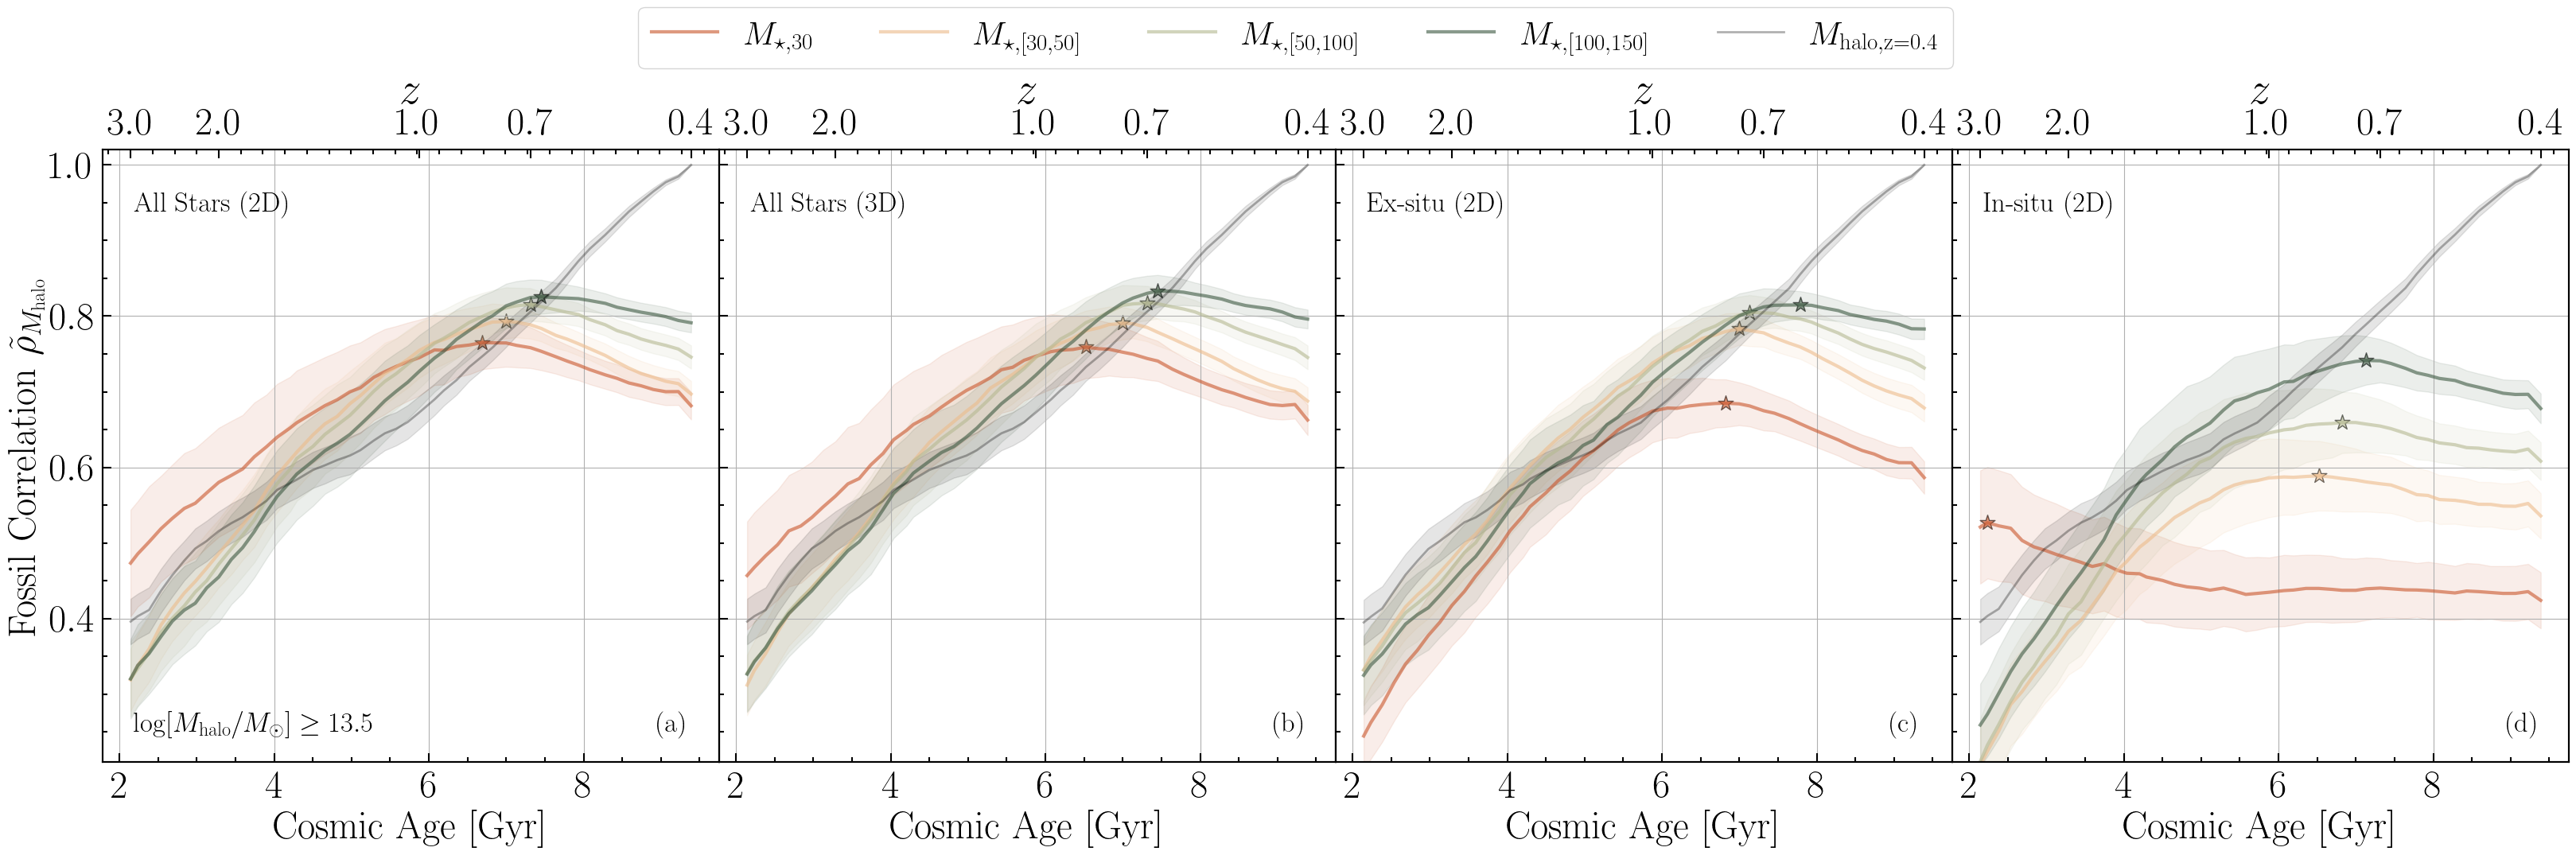

In [19]:
import palettable
snap_list=np.arange(25,73,1)
fig, axlist = plt.subplots(1, 4, figsize=(40, 10),facecolor='none',sharex=True, sharey=True)
axlist=axlist.flatten()
ax1=axlist[0]
plt.subplots_adjust(hspace=0,wspace=0)
sma_list=[30,50,100,150]
color_list = palettable.cartocolors.diverging.Fall_4.mpl_colors[::-1]
mask1=(tab2[mask_exl]['mass_halo']/0.6774>10**13.5)
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_gal'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_gal'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    max_index=np.where(corr_tab==max(corr_tab))[0][0]
    ax1.scatter(age_tab[25:73][max_index],corr_tab[max_index],color=color, alpha=0.6, s=200, marker='*', edgecolors='black')
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=3)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.1)
snapnum_tab=[]
corr_halo_tab=[]
corr_halo_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_halo_tab.append(corr)
    corr_halo_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.3, label=r'$M_{\rm halo,z=0.4}$', lw=2)
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.1)
# corr_err_tab=[]
# for snapnum in range(25,73,1):
#     ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
#     xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
#     mask_pk=(xdata>0)
#     corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
#     corr_tab.append(corr)
#     corr_err_tab.append(corr_err)
#     snapnum_tab.append(snapnum)
# ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab,color='black', alpha=0.6, fmt='h-',
#             capsize=3, capthick=1, elinewidth=1, markersize=9,label=r'$M_{\rm halo}$')
ax1.text(0.05,0.05,r'$\log[M_{\rm halo}/M_\odot]\geq13.5$',transform=ax1.transAxes,fontsize=25)
ax1.set_ylabel(r'{\rm Fossil\ Correlation} $\tilde{\rho}_{M_{\rm halo}}$ ')
ax1.text(0.05,0.9,r'{\rm All Stars (2D)}',transform=ax1.transAxes,fontsize=25)
ax1.text(0.9,0.05,r'{\rm (a)}',transform=ax1.transAxes,fontsize=25)
ax1.set_ylim(0.21,1.02)
ax2=ax1.twiny()
x1,x2=ax1.get_xlim()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1=axlist[1]
sma_list=[30,50,100,150]
color_list = palettable.cartocolors.diverging.Fall_4.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['3d_out_(0, '+str(sma)+')']-tab2[mask_exl][mask1]['3d_out_(0, '+str(sma0)+')'])
        label=r'$M_{\rm \star,['+str(sma0)+','+str(sma)+r']}$'
    elif i==0:
        xdata=np.log10(tab2[mask_exl][mask1]['3d_out_(0, '+str(sma)+')'])
        label=r'$M_{\star,'+str(sma)+r'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label)
    max_index=np.where(corr_tab==max(corr_tab))[0][0]
    ax1.scatter(age_tab[25:73][max_index],corr_tab[max_index],color=color, alpha=0.6, s=200, marker='*', edgecolors='black') 
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=3)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.1)
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.3, label=r'$M_{\rm halo,z=0.4}$', lw=2)
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.1)
ax2=ax1.twiny()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.text(0.05,0.9,r'{\rm All Stars (3D)}',transform=ax1.transAxes,fontsize=25)
ax1.text(0.9,0.05,r'{\rm (b)}',transform=ax1.transAxes,fontsize=25)
ax1.set_ylim(0.21,1.02)
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.08), 
           ncol=len(handles), fontsize=30)
ax1=axlist[2]
color_list = palettable.cartocolors.diverging.Fall_4.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_exs']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_exs'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+r']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_exs'])
        label=r'$M_{\star,'+str(sma)+r'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    max_index=np.where(corr_tab==max(corr_tab))[0][0]
    ax1.scatter(age_tab[25:73][max_index],corr_tab[max_index],color=color, alpha=0.6, s=200, marker='*', edgecolors='black')
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=3)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.1)
snapnum_tab=[]
corr_halo_tab=[]
corr_halo_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_halo_tab.append(corr)
    corr_halo_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.3, label=r'$M_{\rm halo,z=0.4}$', lw=2)
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.1)
ax2=ax1.twiny()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.set_facecolor('white')
ax1.grid()
ax1.text(0.05,0.9,r'{\rm Ex-situ (2D)}',transform=ax1.transAxes,fontsize=25)
ax1.set_ylim(0.21,1.02)
ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
ax1.text(0.9,0.05,r'{\rm (c)}',transform=ax1.transAxes,fontsize=25)
ax1=axlist[3]
color_list = palettable.cartocolors.diverging.Fall_4.mpl_colors[::-1]
for i in range(len(sma_list)):
    sma=sma_list[i]
    if i>0:
        sma0=sma_list[i-1]
    color=color_list[i]
    snapnum_tab=[]
    corr_tab=[]
    corr_err_tab=[]
    if i>0:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_ins']-tab2[mask_exl][mask1]['aper_'+str(sma0)+'_ins'])
        label=r'$M_{\star,['+str(sma0)+','+str(sma)+']}$'
    else:
        xdata=np.log10(tab2[mask_exl][mask1]['aper_'+str(sma)+'_ins'])
        label=r'$M_{\star,'+str(sma)+'}$'
    for snapnum in range(25,73,1):
        ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
        mask_pk=(xdata>0)
        corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk])
        corr_tab.append(corr)
        corr_err_tab.append(corr_err)
        snapnum_tab.append(snapnum)
    # ax1.errorbar(age_tab[25:73],corr_tab,yerr=corr_err_tab, alpha=0.7, fmt='h-', color=color,
    #             capsize=3, capthick=1, elinewidth=1, markersize=9,label=label) 
    max_index=np.where(corr_tab==max(corr_tab))[0][0]
    ax1.scatter(age_tab[25:73][max_index],corr_tab[max_index],color=color, alpha=0.6, s=200, marker='*', edgecolors='black')
    ax1.plot(age_tab[25:73],corr_tab,color=color, alpha=0.6, label=label,lw=3)
    ax1.fill_between(age_tab[25:73],np.array(corr_tab)-np.array(corr_err_tab),np.array(corr_tab)+np.array(corr_err_tab),color=color, alpha=0.1)
snapnum_tab=[]
corr_halo_tab=[]
corr_halo_err_tab=[]
for snapnum in range(25,73,1):
    ydata=np.log10(tab_prog_mass[mask1]['mhalo_past_'+str(snapnum)])
    xdata=np.log10(tab2[mask_exl][mask1]['mass_halo'])
    mask_pk=(xdata>=0)
    corr,corr_err=bootstrap_corr(xdata[mask_pk],ydata[mask_pk],method='spearman')
    corr_halo_tab.append(corr)
    corr_halo_err_tab.append(corr_err)
    snapnum_tab.append(snapnum)
ax1.plot(age_tab[25:73],corr_halo_tab,color='black', alpha=0.3, label=r'$M_{\rm halo,z=0.4}$', lw=2)
ax1.fill_between(age_tab[25:73],np.array(corr_halo_tab)-np.array(corr_halo_err_tab),np.array(corr_halo_tab)+np.array(corr_halo_err_tab),color='black', alpha=0.1)
ax2=ax1.twiny()
ax2.set_xlim(x1,x2)
ax2.set_xticks(age_tab[[25,33,50,59,72]],[r'$3.0$',r'$2.0$',r'$1.0$',r'$0.7$',r'$0.4$'])
ax2.set_xlabel(r'$z$', fontsize=40)
ax1.text(0.05,0.9,r'{\rm In-situ (2D)}',transform=ax1.transAxes,fontsize=25)
ax1.set_ylim(0.21,1.02)
ax1.text(0.9,0.05,r'{\rm (d)}',transform=ax1.transAxes,fontsize=25)
ax1.set_facecolor('white')
ax1.grid()
for ax1 in axlist:
    ax1.set_xlabel(r'\rm Cosmic Age [Gyr]')
fig.savefig(fig_dir+'Fig4.pdf',dpi=100,bbox_inches='tight',transparent=True)